# Supplementary figures S4 and S5 (diurnal analysis)

S4 (diurnal lag-phase curve) and S5 (mean diurnal profiles, daily-averaging check).

Lag-phase: cross-correlate PM2.5 anomaly at hour t with O3 anomaly at hour t+lag (lags -6..+6 h).
Anomaly = value minus that hour-of-day's climatological mean (WITHOUT this, PM2.5's 07 h
peak against O3's 13 h peak manufactures a spurious +5-6 h lag). Daytime = PM2.5 hour 06-19
local (this window reproduces the logged +3 h peak: 0.201 here vs 0.199 logged; lag 0 is
0.162 vs 0.168 logged -- the exact window used earlier was not saved). Radiation control:
regress the same-hour ERA5 radiation anomaly (at the O3 time) out of both series.
S5: mean diurnal profiles + corr(within-day covariance, naive daily product) (expected 0.048).

In [1]:
# Setup
import sys
from pathlib import Path
HERE = Path.cwd().resolve()          # notebooks/ folder
sys.path.insert(0, str(HERE.parent)); sys.path.insert(0, str(HERE.parents[1]))
import sys, glob
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
from style import *   # PM25, O3, NAVY, GREY, RED, LIGHT, ROOT, DATA_OUT, save_fig, panel_label

In [2]:
# Settings (edit here, then Run All)
# Figsize bumped and fonts increased 2026-09-24 (user: text reads small once scaled to the page's textwidth).
FIGSIZE = dict(S04=(7.4, 5.0), S05=(7.4, 4.8))
MARKER, MS = "o", 4.5                    # S4 lines
DAYTIME = (6, 19)                        # local hours used for the lag-phase correlation
LAGS = list(range(-6, 7))
PM25 = PM25_BLUE                         # blue instead of orange in every SI figure (2026-09-23, user request)

 lag_h  r_anomaly  r_anomaly_radiation_controlled  r_naive_no_anomaly     n
    -6      0.038                           0.026              -0.044 34377
    -5      0.065                           0.050              -0.053 34381
    -4      0.089                           0.072              -0.065 34381
    -3      0.110                           0.092              -0.074 34382
    -2      0.128                           0.109              -0.071 34384
    -1      0.146                           0.126              -0.042 34384
     0      0.162                           0.139               0.015 34384
     1      0.178                           0.151               0.093 34384
     2      0.192                           0.160               0.171 34384
     3      0.201                           0.165               0.233 34384
     4      0.201                           0.163               0.271 34357
     5      0.192                           0.153               0.291 34353
     6      

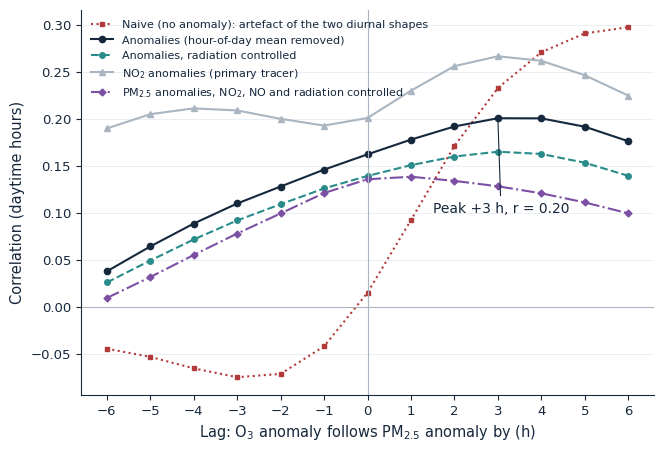

In [3]:
# Analysis
pm = pd.read_excel(ROOT / "Data/COLOMBIA/Hourmean/PM25_hourmean.xlsx", usecols=["Dates", "Bogota"]).rename(columns={"Dates": "t", "Bogota": "pm"})
o3 = pd.read_excel(ROOT / "Data/COLOMBIA/Hourmean/O3_hourmean.xlsx", usecols=["Dates", "Bogota"]).rename(columns={"Dates": "t", "Bogota": "o3"})
for d in (pm, o3): d["t"] = pd.to_datetime(d["t"])
h = pm.merge(o3, on="t", how="outer").sort_values("t").set_index("t")
h = h[~h.index.duplicated()].asfreq("h")
ds = [xr.open_dataset(p) for p in sorted(glob.glob(str(ROOT / "Data/external/era5/bogota_era5_ssrd_*.nc")))]
ds = [d.rename({"valid_time": "time"}) if "valid_time" in d.dims else d for d in ds]
rad = xr.concat(sorted(ds, key=lambda d: d.time.values[0]), dim="time").mean(dim=["latitude", "longitude"])["ssrd"] / 3600.0
rad = rad.to_series(); rad.index = rad.index + pd.Timedelta(hours=-5); rad = rad[~rad.index.duplicated()]
h["rad"] = rad.reindex(h.index)   # ERA5 is UTC; shifted to Bogota local time above (same as external_data.py)
h["hour"] = h.index.hour
for c in ["pm", "o3", "rad"]:
    h[c + "_a"] = h[c] - h.groupby("hour")[c].transform("mean")

def xcorr(lag, lo=DAYTIME[0], hi=DAYTIME[1], control=False, anomaly=True):
    x = h["pm_a" if anomaly else "pm"]; y = h["o3_a" if anomaly else "o3"].shift(-lag)
    r = h["rad_a"].shift(-lag)
    df = pd.DataFrame({"x": x, "y": y, "r": r, "hh": h["hour"]}).dropna()
    df = df[(df.hh >= lo) & (df.hh <= hi)]
    if control:
        A = np.column_stack([np.ones(len(df)), df.r.to_numpy()])
        ex = df.x.to_numpy() - A @ np.linalg.lstsq(A, df.x.to_numpy(), rcond=None)[0]
        ey = df.y.to_numpy() - A @ np.linalg.lstsq(A, df.y.to_numpy(), rcond=None)[0]
        return float(np.corrcoef(ex, ey)[0, 1]), len(df)
    return float(np.corrcoef(df.x, df.y)[0, 1]), len(df)

lags = LAGS
rows = []
for k in lags:
    a, n = xcorr(k); b, _ = xcorr(k, control=True); c, _ = xcorr(k, anomaly=False)
    rows.append(dict(lag_h=k, r_anomaly=a, r_anomaly_radiation_controlled=b, r_naive_no_anomaly=c, n=n))
t = pd.DataFrame(rows); t.to_csv(DATA_OUT / "diurnal_lag_phase.csv", index=False)
pk = t.loc[t.r_anomaly.idxmax()]; pkc = t.loc[t.r_anomaly_radiation_controlled.idxmax()]
print(t.round(3).to_string(index=False))
print(f"peak raw +{int(pk.lag_h)} h r={pk.r_anomaly:.3f}; lag0 {t[t.lag_h==0].r_anomaly.iloc[0]:.3f}; controlled peak +{int(pkc.lag_h)} h r={pkc.r_anomaly_radiation_controlled:.3f}")

fig, ax = plt.subplots(figsize=FIGSIZE['S04'])
ax.plot(t.lag_h, t.r_naive_no_anomaly, ":", color=RED, marker="s", ms=3.5, label="naive (no anomaly): artefact of the two diurnal shapes")
ax.plot(t.lag_h, t.r_anomaly, "-", marker=MARKER, color=NAVY, ms=MS, label="anomalies (hour-of-day mean removed)")
ax.plot(t.lag_h, t.r_anomaly_radiation_controlled, "--o", color=O3, ms=4, label="anomalies, radiation controlled")
# 2026-10-20 (notebook A8 must run first): the same lead-lag for ground NO2, a primary traffic tracer, and for PM2.5 with NO2, NO and radiation regressed out
cp = pd.read_csv(DATA_OUT / "coproduction_hourly_leadlag.csv")
no2c = cp[(cp.series == "no2") & (cp.subset == "all months") & (cp.controls == "none")].set_index("lag_h").r
pmc = cp[(cp.series == "pm25") & (cp.controls == "no2+no+rad")].set_index("lag_h").r
ax.plot(no2c.index, no2c.values, "-^", color=GREY, ms=4, label="NO$_2$ anomalies (primary tracer)")
ax.plot(pmc.index, pmc.values, "-.D", color="#7B4FA3", ms=3.5, label="PM$_{2.5}$ anomalies, NO$_2$, NO and radiation controlled")
ax.axvline(0, color=GREY, lw=0.8); ax.axhline(0, color=GREY, lw=0.8)
ax.annotate(f"peak +{int(pk.lag_h)} h, r = {pk.r_anomaly:.2f}", (pk.lag_h, pk.r_anomaly), xytext=(pk.lag_h - 1.5, pk.r_anomaly - 0.10),
            arrowprops=dict(arrowstyle="-", color=NAVY, lw=0.8), fontsize=10)
ax.set_xlabel("lag: O$_3$ anomaly follows PM$_{2.5}$ anomaly by (h)", fontsize=10.5); ax.set_ylabel("correlation (daytime hours)", fontsize=10.5)
ax.tick_params(labelsize=9.5)
ax.set_xticks(lags); ax.legend(frameon=False, fontsize=8, loc="upper left"); ax.grid(axis="y", color=LIGHT, lw=0.6)
save_fig(fig, "figS04_diurnal_lag_phase")

/var/folders/30/gtfddbxx5z3f_hc8v4br4pkh0000gn/T/ipykernel_39619/4256643113.py:14: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  gm = g.mean().loc[ok]; cov = (g.apply(lambda x: (x.pm * x.rad).mean()).loc[ok] - gm.pm * gm.rad)


saved /path/to/project/Paper/figures/figS05_diurnal_profiles.png
S5: 7 26.0 13 630.6 corr = 0.048 days 3286


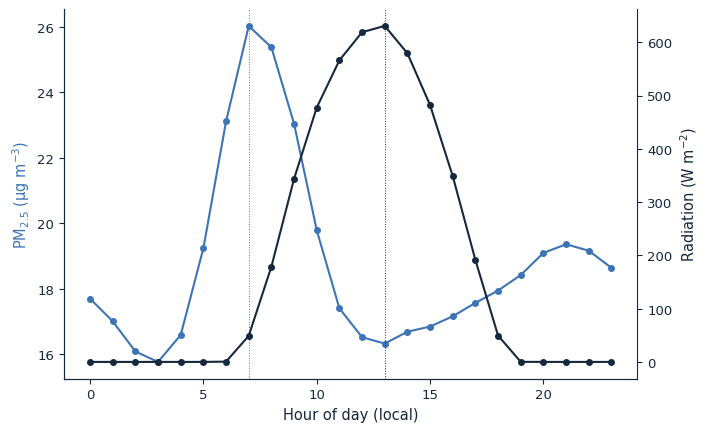

In [4]:
# S5
prof = h.groupby("hour")[["pm", "rad"]].mean()
fig, ax = plt.subplots(figsize=FIGSIZE['S05'])
ax.plot(prof.index, prof.pm, "-o", color=PM25, ms=4, label="PM$_{2.5}$")
ax.set_xlabel("hour of day (local)", fontsize=10.5); ax.set_ylabel("PM$_{2.5}$ (µg m$^{-3}$)", color=PM25, fontsize=10.5)
ax.tick_params(labelsize=9.5, axis="x"); ax.tick_params(axis="y", labelsize=9.5)
ax2 = ax.twinx(); ax2.spines["right"].set_visible(True)
ax2.plot(prof.index, prof.rad, "-o", color=NAVY, ms=4, label="solar radiation"); ax2.set_ylabel("radiation (W m$^{-2}$)", color=NAVY, fontsize=10.5)
ax2.tick_params(axis="y", labelsize=9.5)
ax.axvline(prof.pm.idxmax(), color=PM25, lw=0.7, ls=":"); ax2.axvline(prof.rad.idxmax(), color=NAVY, lw=0.7, ls=":")
# within-day covariance check
d = h[["pm", "rad"]].dropna(); d["date"] = d.index.floor("D")
g = d.groupby("date"); n = g.size(); ok = n[n >= 18].index
gm = g.mean().loc[ok]; cov = (g.apply(lambda x: (x.pm * x.rad).mean()).loc[ok] - gm.pm * gm.rad)
naive = gm.pm * gm.rad
r = float(np.corrcoef(cov, naive)[0, 1])
save_fig(fig, "figS05_diurnal_profiles")
# peak hour/value + corr numbers below are reported in the manuscript caption (09_supplement.tex),
# not as an in-plot title -- keep the two in sync if this cell's numbers ever change.
pd.DataFrame([dict(pm25_peak_hour=int(prof.pm.idxmax()), pm25_peak=prof.pm.max(), rad_peak_hour=int(prof.rad.idxmax()),
                   rad_peak=prof.rad.max(), corr_within_day_cov_vs_naive_product=r, n_days=len(ok))]).to_csv(DATA_OUT / "diurnal_profile_summary.csv", index=False)
print("S5:", prof.pm.idxmax(), round(prof.pm.max(), 1), prof.rad.idxmax(), round(prof.rad.max(), 1), "corr =", round(r, 3), "days", len(ok))